YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed
c:\Projects\KalAnalysis\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 7s 116ms/step - loss: 0.1099 - val_loss: 0.0017
Epoch 2/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 78ms/step - loss: 0.0064 - val_loss: 0.0025
Epoch 3/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 78ms/step - loss: 0.0029 - val_loss: 0.0034
Epoch 4/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 80ms/step - loss: 0.0021 - val_loss: 0.0054
Epoch 5/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - loss: 0.0017 - val_loss: 0.0039
Epoch 6/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - loss: 0.0018 - val_loss: 0.0044
Epoch 7/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - loss: 0.0017 - val_loss: 0.0029
Epoch 8/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 70ms/step - loss: 0.0016 - val_loss: 0.0035
Epoch 9/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - loss: 0.0014 - val_loss: 0.0051
Epoch 10/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step - loss: 0.0017 - val_loss: 0.0029
Epoch 11/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - loss: 0.0015 - val_loss: 0.0027
Epoch 12/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - loss: 0.

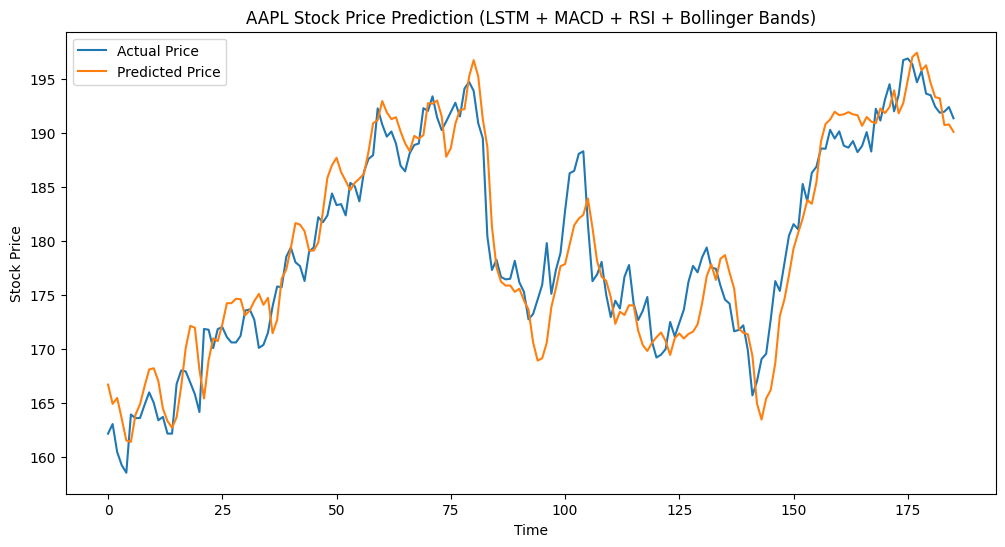

Test Mean Squared Error: 9.1520


In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Step 1: Download stock data
ticker = "AAPL"  # Stock symbol
data = yf.download(ticker, start="2020-01-01", end="2024-01-01")

# Step 2: Calculate technical indicators

# Bollinger Bands
data['MiddleBand'] = data['Close'].rolling(window=20).mean()
data['StdDev'] = data['Close'].rolling(window=20).std()
data['UpperBand'] = data['MiddleBand'] + (2 * data['StdDev'])
data['LowerBand'] = data['MiddleBand'] - (2 * data['StdDev'])

# MACD
data['EMA12'] = data['Close'].ewm(span=12, adjust=False).mean()
data['EMA26'] = data['Close'].ewm(span=26, adjust=False).mean()
data['MACD'] = data['EMA12'] - data['EMA26']
data['Signal_Line'] = data['MACD'].ewm(span=9, adjust=False).mean()

# RSI (Relative Strength Index)
delta = data['Close'].diff()
gain = delta.clip(lower=0)
loss = -1 * delta.clip(upper=0)

avg_gain = gain.rolling(window=14).mean()
avg_loss = loss.rolling(window=14).mean()

rs = avg_gain / avg_loss
data['RSI'] = 100 - (100 / (1 + rs))

# Step 3: Prepare dataset
# Select only the features you want to feed to LSTM
data = data[['Close', 'MiddleBand', 'UpperBand', 'LowerBand', 'MACD', 'Signal_Line', 'RSI']].dropna()

# Scale features
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)

# Step 4: Create sequences for LSTM
X = []
y = []

sequence_length = 60  # last 60 days to predict the next day

for i in range(sequence_length, len(scaled_data)):
    X.append(scaled_data[i-sequence_length:i, 1:])  # use features (skip Close at index 0)
    y.append(scaled_data[i, 0])  # target is Close price

X, y = np.array(X), np.array(y)

# Step 5: Train/test split
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# Step 6: Build the LSTM model
model = Sequential()
model.add(LSTM(units=60, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(LSTM(units=60))
model.add(Dense(1))

model.compile(optimizer='adam', loss='mean_squared_error')

# Step 7: Train the model
history = model.fit(X_train, y_train, epochs=60, batch_size=32, validation_data=(X_test, y_test), verbose=1)

# Step 8: Make predictions
predicted = model.predict(X_test)

# Inverse scale (just the Close price)
close_scaler = MinMaxScaler()
close_scaler.min_, close_scaler.scale_ = scaler.min_[0], scaler.scale_[0]
predicted_prices = close_scaler.inverse_transform(predicted.reshape(-1,1))
real_prices = close_scaler.inverse_transform(y_test.reshape(-1,1))

# Step 9: Plot results
plt.figure(figsize=(12,6))
plt.plot(real_prices, label='Actual Price')
plt.plot(predicted_prices, label='Predicted Price')
plt.title(f"{ticker} Stock Price Prediction (LSTM + MACD + RSI + Bollinger Bands)")
plt.xlabel("Time")
plt.ylabel("Stock Price")
plt.legend()
plt.show()

# Step 10: Final Score
mse = np.mean((real_prices - predicted_prices)**2)
print(f"Test Mean Squared Error: {mse:.4f}")
